# Vidal LSTM Transfer Learning: Panasonic → CMU eVTOL

Experiment entrypoint and audit surface for the Vidal method. Repository modules own the model, CMU adapter, resampling, window construction, normalization, and metrics. This notebook does not retrain Vidal Case 1–4 and does not invent an unfrozen CMU supervised-adaptation protocol.

## Colab bootstrap

This cell only locates or safely clones the repository, mounts Google Drive, and points `VIDAL_ARTIFACT_ROOT` at the existing formal Vidal artifacts. It does not download data, retrain Case 1–4, or start a benchmark run. For a private repository, add a Colab secret named `GITHUB_TOKEN`, enable Notebook access, and grant it read access to this repository.

In [1]:
import os
import shutil
import subprocess
import sys
import time
import tempfile
from pathlib import Path

REPO_NAME = "battery-soc-transfer-benchmark"
REPO_URL = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
COLAB_REPO_ROOT = Path("/content") / REPO_NAME
DRIVE_ARTIFACT_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/outputs")

def is_repo_root(path):
    path = Path(path).expanduser().resolve()
    return (path / "pyproject.toml").is_file() and (path / "src/battery_benchmark").is_dir()

def locate_existing_repo():
    start = Path.cwd().resolve()
    candidates = []
    explicit = os.environ.get("BATTERY_BENCHMARK_ROOT")
    if explicit:
        candidates.append(Path(explicit))
    candidates.extend((start, *start.parents, start / REPO_NAME, COLAB_REPO_ROOT, Path("/workspace") / REPO_NAME))
    for candidate in candidates:
        if is_repo_root(candidate):
            return candidate.expanduser().resolve()
    return None

try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")

repo_root = locate_existing_repo()
if repo_root is None and IN_COLAB:
    os.chdir("/content")
    if COLAB_REPO_ROOT.exists():
        shutil.rmtree(COLAB_REPO_ROOT)
    github_token = userdata.get("GITHUB_TOKEN")
    if not github_token:
        raise RuntimeError("Colab secret GITHUB_TOKEN is missing or Notebook access is disabled.")
    with tempfile.TemporaryDirectory() as temp_dir:
        askpass = Path(temp_dir) / "git-askpass.sh"
        askpass.write_text(
            '#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n'
        )
        askpass.chmod(0o700)
        clone_env = os.environ.copy()
        clone_env.update({
            "GIT_ASKPASS": str(askpass),
            "GIT_TERMINAL_PROMPT": "0",
            "GITHUB_TOKEN": github_token,
        })
        clone_result = subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(COLAB_REPO_ROOT)],
            cwd="/content", env=clone_env, text=True, capture_output=True, check=False,
        )
        clone_env.pop("GITHUB_TOKEN", None)
    del github_token
    if clone_result.returncode != 0:
        if COLAB_REPO_ROOT.exists() and not is_repo_root(COLAB_REPO_ROOT):
            shutil.rmtree(COLAB_REPO_ROOT)
        raise RuntimeError(
            "Authenticated GitHub clone failed. Check GITHUB_TOKEN repository read permission and Colab Notebook access."
        ) from None
    repo_root = COLAB_REPO_ROOT.resolve()

if repo_root is None:
    raise RuntimeError(
        "Repository not found. Set BATTERY_BENCHMARK_ROOT=/absolute/path/to/battery-soc-transfer-benchmark."
    )

os.environ["BATTERY_BENCHMARK_ROOT"] = str(repo_root)
configured_artifact_root = os.environ.get("VIDAL_ARTIFACT_ROOT")
if DRIVE_ARTIFACT_ROOT.is_dir() and not (
    configured_artifact_root and Path(configured_artifact_root).is_dir()
):
    os.environ["VIDAL_ARTIFACT_ROOT"] = str(DRIVE_ARTIFACT_ROOT)

print("Repository:", repo_root)
print("Commit:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=repo_root, text=True).strip())
print("VIDAL_ARTIFACT_ROOT:", os.environ.get("VIDAL_ARTIFACT_ROOT", "NOT_AVAILABLE"))

Mounted at /content/drive
Repository: /content/battery-soc-transfer-benchmark
Commit: f31b7f3dcf43e8ca519223f407138497bc9ea871
VIDAL_ARTIFACT_ROOT: /content/drive/MyDrive/battery_soc_benchmark/outputs


# 0. Status and Experiment Manifest

- Paper: Vidal et al. (2019)
- Method: LSTM SOC estimator with supervised transfer learning
- Canonical source: Panasonic NCR18650PF, 25 °C, Case 1
- Target: CMU Sony-Murata VTC6 eVTOL
- Target reference labels: used only for supervised adaptation/evaluation
- Pseudo labels: not used

In [2]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

RUN_SOURCE_TRAINING = False
RUN_ZERO_SHOT_SMOKE_TEST = False
RUN_FULL_ZERO_SHOT = False  # archived all-mission diagnostic; keep disabled
RUN_SUPERVISED_ADAPTATION = False  # legacy switch; use the per-setting switches below
WRITE_RESULTS = True
SEED = 42

def find_repo_root(start=None):
    start = (start or Path.cwd()).expanduser().resolve()
    checked = []
    candidates = []

    explicit = os.environ.get("BATTERY_BENCHMARK_ROOT")
    if explicit:
        candidates.append(Path(explicit).expanduser())

    candidates.extend((start, *start.parents))
    candidates.extend((
        start / "battery-soc-transfer-benchmark",
        Path("/content/battery-soc-transfer-benchmark"),
        Path("/workspace/battery-soc-transfer-benchmark"),
    ))

    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in checked:
            continue
        checked.append(candidate)
        if (
            (candidate / "pyproject.toml").is_file()
            and (candidate / "src/battery_benchmark").is_dir()
        ):
            return candidate

    inspected = "\n".join(f"  - {path}" for path in checked)
    raise RuntimeError(
        "Could not locate battery-soc-transfer-benchmark. Checked:\n"
        f"{inspected}\n"
        "Set BATTERY_BENCHMARK_ROOT=/absolute/path/to/battery-soc-transfer-benchmark"
    )

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
source_root = str((REPO_ROOT / "src").resolve())
if source_root not in sys.path:
    sys.path.insert(0, source_root)
print("REPO_ROOT:", REPO_ROOT)

from battery_benchmark.datasets.cmu_evtol.vidal_adapter import (
    ADAPTER_VERSION,
    adapt_cmu_dynamic_soc,
    build_cmu_vidal_windows,
    load_cmu_dynamic_soc_for_vidal,
    transform_cmu_records,
)
from battery_benchmark.evaluation.metrics import compute_metrics
from battery_benchmark.preprocessing.normalization import MinMaxNormalizer
from battery_benchmark.reproductions.vidal_2019.model import VidalLSTM
from battery_benchmark.reproductions.vidal_2019.windows import FEATURES
from battery_benchmark.training.checkpointing import load_checkpoint

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GIT_COMMIT = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO_ROOT, text=True).strip()
NOW_UTC = datetime.now(timezone.utc).isoformat()

EXTERNAL_ARTIFACT_ROOT = os.environ.get("VIDAL_ARTIFACT_ROOT")
ARTIFACT_ROOTS = [REPO_ROOT / "outputs"]
if EXTERNAL_ARTIFACT_ROOT:
    ARTIFACT_ROOTS.insert(0, Path(EXTERNAL_ARTIFACT_ROOT).expanduser().resolve())

CMU_BASE_ROOT = REPO_ROOT / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel"
CMU_EXTENSION_ROOT = REPO_ROOT / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel"
CMU_INVENTORY_PATH = REPO_ROOT / "outputs/datasets/cmu_evtol/vidal_adapter_v1/core7_inventory.csv"
REPOSITORY_CASE1_CONFIG = REPO_ROOT / "configs/reproductions/vidal_2019/vidal_case1_panasonic.yaml"
DRIVE_RESULT_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal")
RESULT_ROOT = Path(os.environ.get(
    "VIDAL_CMU_RESULT_ROOT",
    DRIVE_RESULT_ROOT if Path("/content/drive/MyDrive/battery_soc_benchmark/outputs").is_dir()
    else REPO_ROOT / "outputs/benchmarks/panasonic_to_cmu_evtol/vidal",
)).expanduser().resolve()

def discover_canonical_run(roots):
    candidates = []
    for root in roots:
        if root.exists():
            candidates.extend(root.rglob("checkpoints/epoch_515.pt"))
    for checkpoint in sorted(set(candidates), key=lambda p: p.stat().st_mtime, reverse=True):
        run_dir = checkpoint.parent.parent
        scaler = run_dir / "scaler.json"
        config = run_dir / "resolved_config.yaml"
        metadata = run_dir / "run_metadata.json"
        if not all(path.is_file() for path in (scaler, config, metadata)):
            continue
        try:
            payload = torch.load(checkpoint, map_location="cpu", weights_only=False)
            resolved = yaml.safe_load(config.read_text()) or {}
            run_meta = json.loads(metadata.read_text())
        except Exception:
            continue
        checkpoint_cfg = payload.get("config", {})
        dataset = resolved.get("dataset", checkpoint_cfg.get("dataset", run_meta.get("dataset")))
        if (
            dataset == "panasonic_18650pf"
            and run_meta.get("case", 1) == 1
            and (
                "vidal_case1" in run_dir.parts
                or ("vidal_2019" in run_dir.parts and "case1" in run_dir.parts)
            )
            and payload.get("epoch") == 514
            and resolved.get("run_mode") == "formal"
            and resolved.get("development_only") is False
            and resolved.get("epochs") == 515
            and resolved.get("random_seed") == SEED
        ):
            return {
                "run_dir": run_dir, "checkpoint": checkpoint, "scaler": scaler,
                "config": config, "metadata": metadata,
            }
    return None

CANONICAL_RUN = discover_canonical_run(ARTIFACT_ROOTS)
CHECKPOINT_PATH = CANONICAL_RUN["checkpoint"] if CANONICAL_RUN else None
SCALER_PATH = CANONICAL_RUN["scaler"] if CANONICAL_RUN else None
CONFIG_PATH = CANONICAL_RUN["config"] if CANONICAL_RUN else None

manifest = {
    "method": "vidal_lstm_supervised_transfer",
    "paper": "Vidal et al. (2019)",
    "source_dataset": "panasonic_18650pf",
    "target_dataset": "cmu_evtol_vtc6",
    "source_case": 1,
    "source_temperature": "25_degC",
    "features": list(FEATURES),
    "target": "soc_dynamic_reference_not_ground_truth",
    "sampling_interval": "1_s",
    "sequence_length": 50,
    "stride": 50,
    "checkpoint_path": str(CHECKPOINT_PATH) if CHECKPOINT_PATH else None,
    "scaler_path": str(SCALER_PATH) if SCALER_PATH else None,
    "config_path": str(CONFIG_PATH) if CONFIG_PATH else None,
    "random_seed": SEED,
    "device": str(DEVICE),
    "data_version": "cmu_dynamic_capacity_soc_development_v1 + extension4",
    "git_commit": GIT_COMMIT,
    "timestamp": NOW_UTC,
    "implemented_sections": [0, 1, 2, 3, 4, 5, 7, 10, 11],
}
environment = {
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "device": str(DEVICE),
    "cuda_available": torch.cuda.is_available(),
    "git_commit": GIT_COMMIT,
    "timestamp_utc": NOW_UTC,
    "repo_root": str(REPO_ROOT),
    "checkpoint_exists": bool(CHECKPOINT_PATH and CHECKPOINT_PATH.is_file()),
    "scaler_exists": bool(SCALER_PATH and SCALER_PATH.is_file()),
    "run_config_exists": bool(CONFIG_PATH and CONFIG_PATH.is_file()),
    "repository_case1_config_exists": REPOSITORY_CASE1_CONFIG.is_file(),
    "cmu_inventory_exists": CMU_INVENTORY_PATH.is_file(),
    "external_artifact_root": str(EXTERNAL_ARTIFACT_ROOT) if EXTERNAL_ARTIFACT_ROOT else "NOT_AVAILABLE",
}
display(pd.DataFrame(environment.items(), columns=["item", "value"]))
display(manifest)

REPO_ROOT: /content/battery-soc-transfer-benchmark


,item,value
0,python_version,3.13.15
1,pytorch_version,2.11.0+cu128
2,device,cuda
3,cuda_available,True
4,git_commit,f31b7f3dcf43e8ca519223f407138497bc9ea871
5,timestamp_utc,2026-09-16T18:39:32.090675+00:00
6,repo_root,/content/battery-soc-transfer-benchmark
7,checkpoint_exists,True
8,scaler_exists,True
9,run_config_exists,True


{'method': 'vidal_lstm_supervised_transfer',
 'paper': 'Vidal et al. (2019)',
 'source_dataset': 'panasonic_18650pf',
 'target_dataset': 'cmu_evtol_vtc6',
 'source_case': 1,
 'source_temperature': '25_degC',
 'features': ['voltage', 'current', 'temperature'],
 'target': 'soc_dynamic_reference_not_ground_truth',
 'sampling_interval': '1_s',
 'sequence_length': 50,
 'stride': 50,
 'checkpoint_path': '/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt',
 'scaler_path': '/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json',
 'config_path': '/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/resolved_config.yaml',
 'random_seed': 42,
 'device': 'cuda',
 'data_version': 'cmu_dynamic_capacity_soc_development_v1 + extension4',
 'git_commit': 'f31b7f3dcf43e8ca519223f4

# 1. Method Definition

Vidal LSTM consumes voltage, current, and temperature sequences and outputs SOC at every time step. The reproduced architecture is one LSTM layer (hidden size 10) followed by a linear 10→1 head. PyTorch's recurrent-side secondary bias is frozen at zero to preserve the paper-aligned 571 trainable parameters.

- **Case 1:** supervised within-dataset source training/evaluation.
- **Case 2:** Case 1 source weights → supervised target full-train fine-tuning.
- **Case 3:** Case 1 source weights → supervised target partial-train fine-tuning.
- **Case 4:** reconstructed multi-source partial pretraining followed by supervised target full-train fine-tuning.

The method uses real target reference SOC during transfer and no pseudo labels. Each paper method may retain its own source-training procedure. The CMU benchmark standardizes target test cells, isolation rules, reference-label version, and metrics—not source-domain training.

In [3]:
model_config = yaml.safe_load((REPO_ROOT / "configs/reproductions/vidal_2019/model.yaml").read_text()) or {}
case1_config = yaml.safe_load(REPOSITORY_CASE1_CONFIG.read_text()) or {}
method_table = pd.DataFrame([
    ("feature order", list(FEATURES)),
    ("sequence length", case1_config.get("seq_len", "NOT_CONFIRMED")),
    ("sampling interval", 1.0 / case1_config["resample_hz"] if case1_config.get("resample_hz") else "NOT_CONFIRMED"),
    ("stride", case1_config.get("stride", "NOT_CONFIRMED")),
    ("hidden size", model_config.get("hidden_size", "NOT_CONFIRMED")),
    ("LSTM layers", model_config.get("num_layers", "NOT_CONFIRMED")),
    ("dropout", model_config.get("dropout", "NOT_CONFIRMED")),
    ("optimizer", "Adam (Case 1 code)"),
    ("learning rate", case1_config.get("learning_rate", "NOT_CONFIRMED")),
    ("batch size", case1_config.get("batch_size", "NOT_CONFIRMED")),
    ("loss", "masked MSE (Case 1 code)"),
], columns=["setting", "value"])
display(method_table)

,setting,value
0,feature order,"[voltage, current, temperature]"
1,sequence length,50
2,sampling interval,1.0
3,stride,50
4,hidden size,10
5,LSTM layers,1
6,dropout,0.0
7,optimizer,Adam (Case 1 code)
8,learning rate,0.01
9,batch size,512


# 2. Original-Paper Reproduction: Cases 1–4

Existing artifacts are inventoried only; nothing is retrained. Paper-reproduction metrics remain separate from CMU benchmark metrics. A legacy Case 4 config still says “NOT YET IMPLEMENTED” even though the current Case 4 implementation exists; this is reported as an audit warning rather than silently corrected here.

In [4]:
CASE_CONFIGS = {
    1: REPOSITORY_CASE1_CONFIG,
    2: REPO_ROOT / "configs/reproductions/vidal_2019/vidal_case2.yaml",
    3: REPO_ROOT / "configs/reproductions/vidal_2019/vidal_case3.yaml",
    4: REPO_ROOT / "configs/reproductions/vidal_2019/vidal_case4.yaml",
}
CASE_TYPES = {
    1: "supervised source training",
    2: "supervised full-target fine-tuning",
    3: "supervised partial-target fine-tuning",
    4: "multi-source pretraining + supervised target fine-tuning",
}

def identify_case(metadata, path):
    if metadata.get("case") in {2, 3, 4}:
        return int(metadata["case"])
    if metadata.get("dataset") in {"panasonic_18650pf", "lg_hg2", "samsung_30t"}:
        if "case2" not in str(path).lower() and "case3" not in str(path).lower() and "case4" not in str(path).lower():
            return 1
    return None

artifact_rows = []
for root in ARTIFACT_ROOTS:
    if not root.exists():
        continue
    for metadata_path in root.rglob("run_metadata.json"):
        try:
            metadata = json.loads(metadata_path.read_text())
        except Exception:
            continue
        case = identify_case(metadata, metadata_path)
        if case is None:
            continue
        run_dir = metadata_path.parent
        metrics_path = run_dir / "metrics.json"
        metrics = json.loads(metrics_path.read_text()) if metrics_path.is_file() else {}
        checkpoint = run_dir / "checkpoints/epoch_515.pt"
        scaler = run_dir / "scaler.json"
        config = run_dir / "resolved_config.yaml"
        artifact_rows.append({
            "case": case,
            "source dataset": metadata.get("source_dataset", metadata.get("dataset", "NOT_CONFIRMED") if case == 1 else "NOT_CONFIRMED"),
            "target dataset": metadata.get("target_dataset", "same_as_source" if case == 1 else "NOT_CONFIRMED"),
            "temperature": "25_degC" if case == 1 and metadata.get("dataset") == "panasonic_18650pf" else "NOT_CONFIRMED",
            "training/adaptation type": CASE_TYPES[case],
            "checkpoint": str(checkpoint) if checkpoint.is_file() else "NOT_AVAILABLE",
            "scaler": str(scaler) if scaler.is_file() else "NOT_AVAILABLE",
            "config": str(config) if config.is_file() else "NOT_AVAILABLE",
            "MAE": metrics.get("mae_fraction", metrics.get("mae", "NOT_AVAILABLE")),
            "RMSE": metrics.get("rmse_fraction", metrics.get("rmse", "NOT_AVAILABLE")),
            "same_run_artifacts": all(path.is_file() and path.parent == run_dir for path in (scaler, config))
                and checkpoint.is_file() and checkpoint.parent.parent == run_dir,
            "status": "AVAILABLE" if metrics_path.is_file() else "PARTIAL_ARTIFACT",
            "run_dir": str(run_dir),
        })

case_inventory_rows = []
for case in range(1, 5):
    matching = [row for row in artifact_rows if row["case"] == case]
    if matching:
        case_inventory_rows.extend(matching)
    else:
        case_inventory_rows.append({
            "case": case, "source dataset": "NOT_AVAILABLE", "target dataset": "NOT_AVAILABLE",
            "temperature": "NOT_AVAILABLE", "training/adaptation type": CASE_TYPES[case],
            "checkpoint": "NOT_AVAILABLE", "scaler": "NOT_AVAILABLE",
            "config": str(CASE_CONFIGS[case]) if CASE_CONFIGS[case].is_file() else "NOT_AVAILABLE",
            "MAE": "NOT_AVAILABLE", "RMSE": "NOT_AVAILABLE",
            "same_run_artifacts": False, "status": "NOT_AVAILABLE", "run_dir": "NOT_AVAILABLE",
        })
case_inventory = pd.DataFrame(case_inventory_rows)
display(case_inventory)

case4_text = CASE_CONFIGS[4].read_text() if CASE_CONFIGS[4].is_file() else ""
case4_artifact_exists = any(row["case"] == 4 and row["status"] == "AVAILABLE" for row in artifact_rows)
reproduction_audit_warnings = []
if "NOT YET IMPLEMENTED" in case4_text:
    reproduction_audit_warnings.append(
        "Legacy vidal_case4.yaml says NOT YET IMPLEMENTED while current case4.py is implemented"
        + (" and formal artifacts were found." if case4_artifact_exists else ".")
    )
display(pd.DataFrame({"audit_warning": reproduction_audit_warnings or ["none"]}))

paper_comparison = pd.DataFrame([{
    "case": case,
    "paper_MAE": "NOT_CONFIRMED",
    "paper_RMSE": "NOT_CONFIRMED",
    "reproduction_MAE": next((row["MAE"] for row in artifact_rows if row["case"] == case), "NOT_AVAILABLE"),
    "reproduction_RMSE": next((row["RMSE"] for row in artifact_rows if row["case"] == case), "NOT_AVAILABLE"),
} for case in range(1, 5)])
display(paper_comparison)
print("RUN_SOURCE_TRAINING =", RUN_SOURCE_TRAINING, "— source retraining is outside this notebook.")

,case,source dataset,target dataset,temperature,training/adaptation type,checkpoint,scaler,config,MAE,RMSE,same_run_artifacts,status,run_dir
0,1,samsung_30t,same_as_source,NOT_CONFIRMED,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.334827,0.397745,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
1,1,samsung_30t,same_as_source,NOT_CONFIRMED,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.334835,0.397757,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
2,1,lg_hg2,same_as_source,NOT_CONFIRMED,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.356001,0.423745,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
3,1,lg_hg2,same_as_source,NOT_CONFIRMED,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.356014,0.423762,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
4,1,panasonic_18650pf,same_as_source,25_degC,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.317581,0.378034,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
5,1,panasonic_18650pf,same_as_source,25_degC,supervised source training,NOT_AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.317595,0.378052,False,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
6,1,samsung_30t,same_as_source,NOT_CONFIRMED,supervised source training,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.017129,0.028079,True,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
7,1,lg_hg2,same_as_source,NOT_CONFIRMED,supervised source training,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.011237,0.018452,True,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
8,1,panasonic_18650pf,same_as_source,25_degC,supervised source training,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,0.01897,0.030528,True,AVAILABLE,/content/drive/MyDrive/battery_soc_benchmark/o...
9,2,NOT_AVAILABLE,NOT_AVAILABLE,NOT_AVAILABLE,supervised full-target fine-tuning,NOT_AVAILABLE,NOT_AVAILABLE,/content/battery-soc-transfer-benchmark/config...,NOT_AVAILABLE,NOT_AVAILABLE,False,NOT_AVAILABLE,NOT_AVAILABLE


,audit_warning
0,Legacy vidal_case4.yaml says NOT YET IMPLEMENT...


,case,paper_MAE,paper_RMSE,reproduction_MAE,reproduction_RMSE
0,1,NOT_CONFIRMED,NOT_CONFIRMED,0.334827,0.397745
1,2,NOT_CONFIRMED,NOT_CONFIRMED,NOT_AVAILABLE,NOT_AVAILABLE
2,3,NOT_CONFIRMED,NOT_CONFIRMED,0.014935,0.023068
3,4,NOT_CONFIRMED,NOT_CONFIRMED,0.013609,0.020797


RUN_SOURCE_TRAINING = False — source retraining is outside this notebook.


# 3. Canonical Source Checkpoint and Scaler

The only accepted source pair is Panasonic 25 °C Case 1 `checkpoints/epoch_515.pt` plus sibling `scaler.json` and `resolved_config.yaml` from that same completed formal run. Case 2 scalers and cross-directory artifact mixing are rejected.

In [5]:
MODEL = None
SCALER = None
CHECKPOINT = None
SOURCE_SYNTHETIC_STATUS = "NOT_RUN"
source_inventory = {
    "checkpoint_status": "NOT_AVAILABLE",
    "scaler_status": "NOT_AVAILABLE",
    "config_status": "NOT_AVAILABLE",
    "same_run_directory": "NOT_RUN",
    "checkpoint_config_match": "NOT_RUN",
    "scaler_matches_checkpoint_state": "NOT_RUN",
    "model_loaded": "NOT_RUN",
    "synthetic_inference": "NOT_RUN",
    "source_scaler_only": "NOT_RUN",
}

if CANONICAL_RUN:
    CHECKPOINT = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    resolved = yaml.safe_load(CONFIG_PATH.read_text()) or {}
    scaler_json = json.loads(SCALER_PATH.read_text())
    checkpoint_config = CHECKPOINT.get("config", {})
    same_run = (
        CHECKPOINT_PATH.parent.parent == SCALER_PATH.parent
        == CONFIG_PATH.parent == CANONICAL_RUN["metadata"].parent
    )
    config_match = all(
        resolved.get(key) == checkpoint_config.get(key)
        for key in ("dataset", "seq_len", "stride", "random_seed", "epochs", "run_mode", "development_only")
    )
    MODEL = VidalLSTM().to(DEVICE)
    SCALER = MinMaxNormalizer()
    load_checkpoint(CHECKPOINT_PATH, MODEL, normalizer=SCALER, device=DEVICE)
    checkpoint_scaler = SCALER.state_dict()
    json_min = scaler_json.get("feature_min", scaler_json.get("min"))
    json_max = scaler_json.get("feature_max", scaler_json.get("max"))
    scaler_matches = (
        json_min is not None and json_max is not None
        and np.array_equal(np.asarray(json_min), np.asarray(checkpoint_scaler["min"]))
        and np.array_equal(np.asarray(json_max), np.asarray(checkpoint_scaler["max"]))
    )
    source_only = (
        scaler_json.get("dataset") == "panasonic_18650pf"
        and scaler_json.get("fit_split") == "full_train"
        and scaler_json.get("feature_names") == list(FEATURES)
    )
    if not (same_run and config_match and scaler_matches and source_only):
        raise RuntimeError("Canonical Case 1 checkpoint/scaler/config provenance validation failed")
    MODEL.eval()
    with torch.no_grad():
        synthetic = torch.zeros((2, 50, 3), dtype=torch.float32, device=DEVICE)
        synthetic_prediction = MODEL(synthetic).cpu().numpy()
    synthetic_ok = (
        synthetic_prediction.shape == (2, 50)
        and np.isfinite(synthetic_prediction).all()
        and CHECKPOINT.get("epoch") == 514
    )
    SOURCE_SYNTHETIC_STATUS = "PASS" if synthetic_ok else "FAIL"
    source_inventory.update({
        "checkpoint_status": "PASS",
        "checkpoint_size_bytes": CHECKPOINT_PATH.stat().st_size,
        "checkpoint_mtime_utc": datetime.fromtimestamp(CHECKPOINT_PATH.stat().st_mtime, timezone.utc).isoformat(),
        "checkpoint_keys": sorted(CHECKPOINT),
        "state_dict_parameter_shapes": {
            name: list(value.shape) for name, value in CHECKPOINT["model_state_dict"].items()
        },
        "checkpoint_epoch_zero_based": CHECKPOINT.get("epoch"),
        "input_dimension": MODEL.input_size,
        "sequence_length": resolved.get("seq_len"),
        "scaler_status": "PASS",
        "config_status": "PASS",
        "scaler_feature_order": scaler_json.get("feature_names", "NOT_CONFIRMED"),
        "scaler_feature_min": json_min,
        "scaler_feature_max": json_max,
        "scaler_fit_split": scaler_json.get("fit_split", "NOT_CONFIRMED"),
        "same_run_directory": "PASS" if same_run else "FAIL",
        "checkpoint_config_match": "PASS" if config_match else "FAIL",
        "scaler_matches_checkpoint_state": "PASS" if scaler_matches else "FAIL",
        "source_scaler_only": "PASS" if source_only else "FAIL",
        "model_loaded": "PASS",
        "synthetic_inference": SOURCE_SYNTHETIC_STATUS,
        "synthetic_input_shape": list(synthetic.shape),
        "synthetic_output_shape": list(synthetic_prediction.shape),
        "synthetic_prediction_min": float(synthetic_prediction.min()),
        "synthetic_prediction_max": float(synthetic_prediction.max()),
        "synthetic_nonfinite_count": int((~np.isfinite(synthetic_prediction)).sum()),
    })
display(pd.DataFrame(source_inventory.items(), columns=["check", "value"]))
if MODEL is None:
    print("NOT_AVAILABLE: set VIDAL_ARTIFACT_ROOT to a root containing the canonical formal Case 1 run.")

,check,value
0,checkpoint_status,PASS
1,scaler_status,PASS
2,config_status,PASS
3,same_run_directory,PASS
4,checkpoint_config_match,PASS
5,scaler_matches_checkpoint_state,PASS
6,model_loaded,PASS
7,synthetic_inference,PASS
8,source_scaler_only,PASS
9,checkpoint_size_bytes,14373


# 4. CMU Adapter and Input QC

The fixed core7 set is audited with the repository's real interfaces:

- `battery_benchmark.datasets.cmu_evtol.vidal_adapter.load_cmu_dynamic_soc_for_vidal()`
- `battery_benchmark.datasets.cmu_evtol.vidal_adapter.build_cmu_vidal_windows()`

No alternate loader, SOC calculator, resampler, or window builder is implemented here. The adapter calls `resample_vidal_record(..., clip_soc=False)`; the protocol config also sets `sampling.soc_clipping: false`.

In [6]:
CORE7 = {
    "VAH01": ("baseline", CMU_BASE_ROOT / "VAH01_dynamic_soc.parquet"),
    "VAH17": ("baseline", CMU_BASE_ROOT / "VAH17_dynamic_soc.parquet"),
    "VAH27": ("baseline", CMU_BASE_ROOT / "VAH27_dynamic_soc.parquet"),
    "VAH30": ("35_degC", CMU_EXTENSION_ROOT / "VAH30_dynamic_soc.parquet"),
    "VAH15": ("1000_s_cruise", CMU_EXTENSION_ROOT / "VAH15_dynamic_soc.parquet"),
    "VAH12": ("400_s_cruise", CMU_EXTENSION_ROOT / "VAH12_dynamic_soc.parquet"),
    "VAH11": ("20_percent_lower_discharge_power", CMU_EXTENSION_ROOT / "VAH11_dynamic_soc.parquet"),
}
adapter_protocol_path = REPO_ROOT / "configs/datasets/cmu_evtol/protocols/cmu_evtol_vidal_adapter_v1.yaml"
adapter_protocol = yaml.safe_load(adapter_protocol_path.read_text()) or {}
committed_inventory = pd.read_csv(CMU_INVENTORY_PATH) if CMU_INVENTORY_PATH.is_file() else pd.DataFrame()

inventory_rows, feature_stats = [], []
for cell_id, (condition, path) in CORE7.items():
    frozen = committed_inventory.loc[committed_inventory["cell_id"] == cell_id]
    frozen = frozen.iloc[0].to_dict() if len(frozen) else {}
    row = {
        "cell_id": cell_id, "condition": condition,
        "file_path": str(path.relative_to(REPO_ROOT)) if path.is_file() else "NOT_AVAILABLE",
        "number_of_missions": frozen.get("vidal_records", "NOT_AVAILABLE"),
        "number_of_windows": frozen.get("vidal_windows", "NOT_AVAILABLE"),
        "sampling_interval": "1_s",
        "sequence_length": 50,
        "feature_columns": list(FEATURES),
        "target_column": "soc_dynamic",
        "SOC_min": frozen.get("soc_min", "NOT_AVAILABLE"),
        "SOC_max": frozen.get("soc_max", "NOT_AVAILABLE"),
        "has_nan": bool(frozen.get("nonfinite_count", 1)) if frozen else "NOT_AVAILABLE",
        "has_inf": bool(frozen.get("nonfinite_count", 1)) if frozen else "NOT_AVAILABLE",
    }
    inventory_rows.append(row)
    if path.is_file():
        raw = pd.read_parquet(path, columns=["voltage_v", "current_a", "Temperature__C", "soc_dynamic"])
        for source, feature in (("voltage_v", "voltage"), ("current_a", "current"), ("Temperature__C", "temperature")):
            values = raw[source].to_numpy(float)
            feature_stats.append({
                "cell_id": cell_id, "feature": feature,
                "min": float(values.min()), "max": float(values.max()),
                "mean": float(values.mean()), "std": float(values.std()),
                "nonfinite": int((~np.isfinite(values)).sum()),
            })
cmu_inventory = pd.DataFrame(inventory_rows)
cmu_feature_stats = pd.DataFrame(feature_stats)
display(cmu_inventory)
display(cmu_feature_stats)

,cell_id,condition,file_path,number_of_missions,number_of_windows,sampling_interval,sequence_length,feature_columns,target_column,SOC_min,SOC_max,has_nan,has_inf
0,VAH01,baseline,outputs/datasets/cmu_evtol/dynamic_capacity_so...,828,15732,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.259288,1.0,False,False
1,VAH17,baseline,outputs/datasets/cmu_evtol/dynamic_capacity_so...,980,18620,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.240304,1.0,False,False
2,VAH27,baseline,outputs/datasets/cmu_evtol/dynamic_capacity_so...,572,10868,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.286486,1.0,False,False
3,VAH30,35_degC,outputs/datasets/cmu_evtol/dynamic_capacity_so...,900,17100,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.273501,1.0,False,False
4,VAH15,1000_s_cruise,outputs/datasets/cmu_evtol/dynamic_capacity_so...,542,12466,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.205660,1.0,False,False
5,VAH12,400_s_cruise,outputs/datasets/cmu_evtol/dynamic_capacity_so...,2302,25322,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.406336,1.0,False,False
6,VAH11,20_percent_lower_discharge_power,outputs/datasets/cmu_evtol/dynamic_capacity_so...,2202,41838,1_s,50,"[voltage, current, temperature]",soc_dynamic,0.349038,1.0,False,False


,cell_id,feature,min,max,mean,std,nonfinite
0,VAH01,voltage,2.500111,4.023581,3.697167,0.213873,0
1,VAH01,current,-21.622623,-0.066428,-5.041393,4.893118,0
2,VAH01,temperature,20.150858,67.949303,29.268621,4.825051,0
3,VAH17,voltage,2.500229,4.022597,3.714688,0.194285,0
4,VAH17,current,-21.621639,-0.064458,-3.071504,4.378027,0
5,VAH17,temperature,21.724371,65.909271,27.840263,5.590431,0
6,VAH27,voltage,2.500111,4.023542,3.730311,0.184407,0
7,VAH27,current,-21.606074,-0.061700,-2.963098,4.266542,0
8,VAH27,temperature,19.510382,64.897156,26.567969,5.391109,0
9,VAH30,voltage,2.797650,4.030920,3.734081,0.173582,0


In [7]:
# Real adapter/window audit, processed one cell at a time.
deep_qc_rows = []
for cell_id, (_, path) in CORE7.items():
    if not path.is_file():
        deep_qc_rows.append({"cell_id": cell_id, "status": "NOT_AVAILABLE"})
        continue
    adapted = load_cmu_dynamic_soc_for_vidal([path], target_hz=1.0)
    windows = build_cmu_vidal_windows(adapted.records, seq_len=50, stride=50, keep_incomplete=False)
    by_order = {int(record.metadata["sequence_order"]): record for record in adapted.records}
    time_failures = sum(
        int(np.any(np.diff(record.data["timestamp"].to_numpy(float)) <= 0))
        for record in adapted.records
    )
    cross_mission = 0
    target_last_mismatch = 0
    keys = []
    for index, meta in enumerate(windows.metadata):
        record = by_order[int(meta["sequence_order"])]
        start, end = int(meta["window_start"]), int(meta["window_end"])
        if meta["mission_cycle_id"] != record.metadata["mission_cycle_id"] or end > len(record.data):
            cross_mission += 1
        expected_target = float(record.data["soc"].iloc[end - 1])
        if not np.array_equal(np.asarray(windows.y[index, int(meta["valid_length"]) - 1]), np.asarray(expected_target, dtype=np.float32)):
            target_last_mismatch += 1
        keys.append((cell_id, meta["mission_cycle_id"], start, end))
    soc_values = np.concatenate([record.data["soc"].to_numpy(float) for record in adapted.records])
    soc_unit = "fraction_0_1" if soc_values.min() >= 0 and soc_values.max() <= 1 else (
        "percent_0_100" if soc_values.min() >= 0 and soc_values.max() <= 100 else "NOT_CONFIRMED"
    )
    deep_qc_rows.append({
        "cell_id": cell_id, "status": "PASS",
        "records": len(adapted.records), "windows": len(windows.X),
        "window_shape": list(windows.X.shape[1:]),
        "time_order_failure_count": time_failures,
        "cross_mission_window_count": cross_mission,
        "target_last_mismatch_count": target_last_mismatch,
        "duplicate_window_count": len(keys) - len(set(keys)),
        "soc_unit": soc_unit,
        "soc_min": float(soc_values.min()), "soc_max": float(soc_values.max()),
        "nonfinite_count": int((~np.isfinite(windows.X)).sum() + (~np.isfinite(windows.y)).sum()),
        "soc_clipping_count": int(adapted.inventory["soc_clipping_count"].sum()),
    })
    del windows, adapted
deep_qc = pd.DataFrame(deep_qc_rows)
display(deep_qc)

assert (deep_qc["status"] == "PASS").all()
for column in (
    "time_order_failure_count", "cross_mission_window_count", "target_last_mismatch_count",
    "duplicate_window_count", "nonfinite_count", "soc_clipping_count",
):
    assert int(deep_qc[column].sum()) == 0, column
assert set(deep_qc["soc_unit"]) == {"fraction_0_1"}
assert all(shape == [50, 3] for shape in deep_qc["window_shape"])
assert adapter_protocol["sampling"]["soc_clipping"] is False

adapter_qc = {
    "adapter_version": ADAPTER_VERSION,
    "feature_order": list(FEATURES),
    "feature_order_match": tuple(FEATURES) == ("voltage", "current", "temperature"),
    "cross_mission_window_count": int(deep_qc["cross_mission_window_count"].sum()),
    "target_last_mismatch_count": int(deep_qc["target_last_mismatch_count"].sum()),
    "duplicate_window_count": int(deep_qc["duplicate_window_count"].sum()),
    "nonfinite_count": int(deep_qc["nonfinite_count"].sum()),
    "soc_unit": "fraction_0_1",
    "soc_clipping_enabled": False,
    "soc_clipping_count": int(deep_qc["soc_clipping_count"].sum()),
    "clipping_evidence": "vidal_adapter._resample_cmu_record -> resample_vidal_record(clip_soc=False); protocol sampling.soc_clipping=false",
    "cmu_scaler_refit": False,
}
display(pd.DataFrame(adapter_qc.items(), columns=["check", "value"]))

,cell_id,status,records,windows,window_shape,time_order_failure_count,cross_mission_window_count,target_last_mismatch_count,duplicate_window_count,soc_unit,soc_min,soc_max,nonfinite_count,soc_clipping_count
0,VAH01,PASS,847,18360,"[50, 3]",0,0,0,0,fraction_0_1,0.259288,1.0,0,0
1,VAH17,PASS,1002,21683,"[50, 3]",0,0,0,0,fraction_0_1,0.240304,1.0,0,0
2,VAH27,PASS,586,12771,"[50, 3]",0,0,0,0,fraction_0_1,0.286486,1.0,0,0
3,VAH30,PASS,919,19855,"[50, 3]",0,0,0,0,fraction_0_1,0.273501,1.0,0,0
4,VAH15,PASS,553,14061,"[50, 3]",0,0,0,0,fraction_0_1,0.205660,1.0,0,0
5,VAH12,PASS,2349,32137,"[50, 3]",0,0,0,0,fraction_0_1,0.406336,1.0,0,0
6,VAH11,PASS,2247,48236,"[50, 3]",0,0,0,0,fraction_0_1,0.349038,1.0,0,0


,check,value
0,adapter_version,cmu_evtol_to_vidal_adapter_v1
1,feature_order,"[voltage, current, temperature]"
2,feature_order_match,True
3,cross_mission_window_count,0
4,target_last_mismatch_count,0
5,duplicate_window_count,0
6,nonfinite_count,0
7,soc_unit,fraction_0_1
8,soc_clipping_enabled,False
9,soc_clipping_count,0


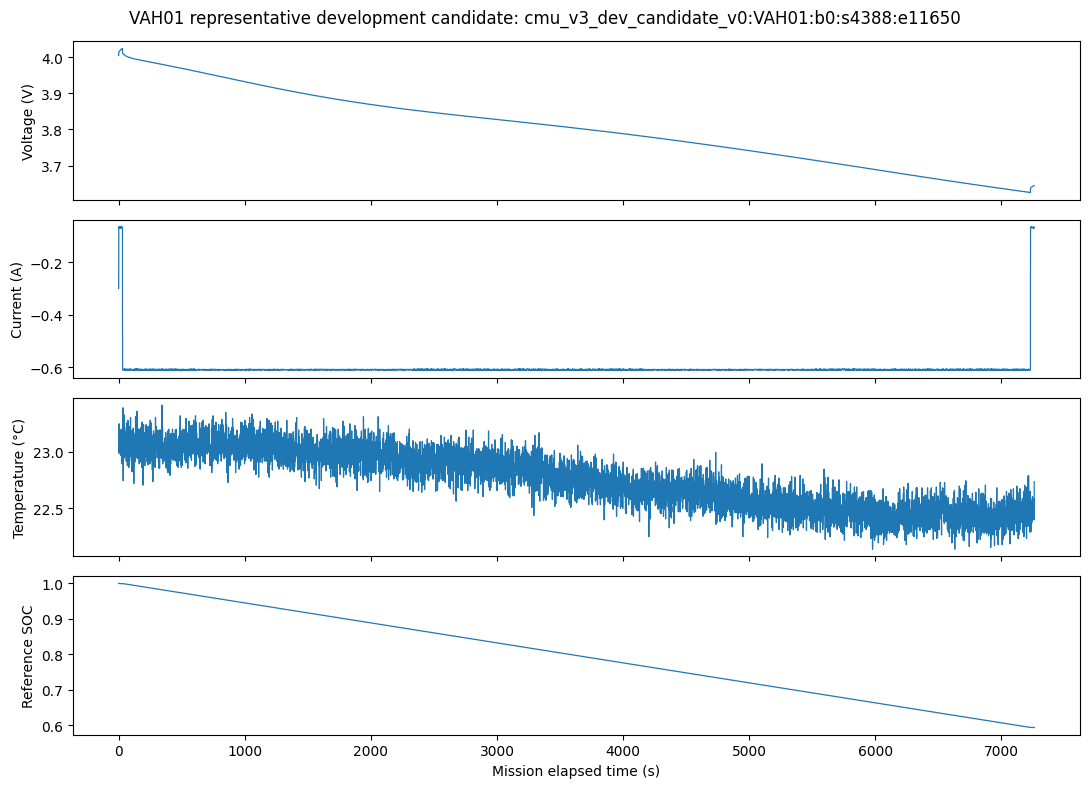

,feature,cmu_min,cmu_max,source_min,source_max
0,current,-21.622623,-0.042566,-18.853415,10.280233
1,temperature,15.933163,68.078293,21.781981,30.439018
2,voltage,2.500013,4.030920,2.511016,4.207847


,cell_id,feature,min,max,mean,std,outside_source_range_fraction
0,VAH01,voltage,-0.006427,0.891406,0.699039,0.126042,0.000008
1,VAH01,current,-0.095052,0.644855,0.474092,0.167954,0.005738
2,VAH01,temperature,-0.188416,5.332924,0.864804,0.557356,0.374750
3,VAH17,voltage,-0.006357,0.890826,0.709365,0.114498,0.000004
4,VAH17,current,-0.095018,0.644923,0.541707,0.150274,0.011117
5,VAH17,temperature,-0.006655,5.097274,0.699810,0.645767,0.356600
6,VAH27,voltage,-0.006427,0.891383,0.718572,0.108677,0.000007
7,VAH27,current,-0.094484,0.645018,0.545428,0.146447,0.007190
8,VAH27,temperature,-0.262399,4.980361,0.552844,0.622743,0.369802
9,VAH30,voltage,0.168923,0.895731,0.720794,0.102298,0.000000


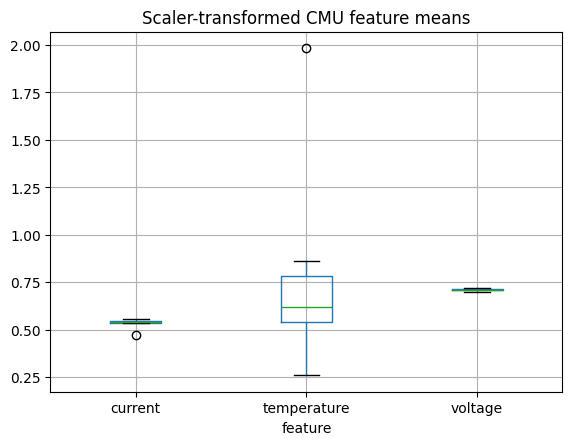

In [8]:
# Three allowed diagnostics only.
vah01_path = CORE7["VAH01"][1]
if vah01_path.is_file():
    vah01 = pd.read_parquet(vah01_path)
    mission_id = vah01["mission_cycle_id"].iloc[0]
    mission = vah01[vah01["mission_cycle_id"] == mission_id]
    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    for ax, column, label in zip(
        axes,
        ["voltage_v", "current_a", "Temperature__C", "soc_dynamic"],
        ["Voltage (V)", "Current (A)", "Temperature (°C)", "Reference SOC"],
    ):
        ax.plot(mission["elapsed_candidate_s"], mission[column], linewidth=0.9)
        ax.set_ylabel(label)
    axes[-1].set_xlabel("Mission elapsed time (s)")
    fig.suptitle(f"VAH01 representative development candidate: {mission_id}")
    fig.tight_layout()
    plt.show()

SCALER_RANGE_QC_STATUS = "NOT_RUN"
transformed_stats = pd.DataFrame()
range_comparison = pd.DataFrame()
if SCALER is None:
    print("NOT_RUN: Panasonic scaler range, out-of-range ratios, and transformed distributions require canonical artifacts.")
else:
    state = SCALER.state_dict()
    source_ranges = pd.DataFrame({
        "feature": list(FEATURES), "source_min": state["min"], "source_max": state["max"]
    })
    range_comparison = cmu_feature_stats.groupby("feature", as_index=False).agg(
        cmu_min=("min", "min"), cmu_max=("max", "max")
    ).merge(source_ranges, on="feature")
    display(range_comparison)
    rows = []
    for cell_id, (_, path) in CORE7.items():
        raw = pd.read_parquet(path, columns=["voltage_v", "current_a", "Temperature__C"])
        x = raw.rename(columns={
            "voltage_v": "voltage", "current_a": "current", "Temperature__C": "temperature"
        })[list(FEATURES)].to_numpy(np.float32)
        transformed = SCALER.transform(x)
        for index, feature in enumerate(FEATURES):
            values = transformed[:, index]
            rows.append({
                "cell_id": cell_id, "feature": feature,
                "min": float(values.min()), "max": float(values.max()),
                "mean": float(values.mean()), "std": float(values.std()),
                "outside_source_range_fraction": float(np.mean((values < 0) | (values > 1))),
            })
    transformed_stats = pd.DataFrame(rows)
    display(transformed_stats)
    transformed_stats.boxplot(column="mean", by="feature")
    plt.suptitle("")
    plt.title("Scaler-transformed CMU feature means")
    plt.show()
    SCALER_RANGE_QC_STATUS = "PASS"

# 5. Zero-Shot Evaluation

Strict zero-shot means canonical Panasonic Case 1 checkpoint + frozen Panasonic Case 1 scaler + no CMU parameter update + no CMU scaler fitting + direct CMU inference. The smoke test uses VAH01 and at most three candidates, never writes formal results, and evaluates each window at its final target time point.

In [9]:
from torch.utils.data import DataLoader, TensorDataset

def state_hash(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        value = state[name]
        digest.update(name.encode())
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

def json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

def detect_soc_unit(values):
    values = np.asarray(values, dtype=float)
    if np.isfinite(values).all() and values.min() >= 0 and values.max() <= 1:
        return "fraction_0_1"
    if np.isfinite(values).all() and values.min() >= 0 and values.max() <= 100:
        return "percent_0_100"
    return "NOT_CONFIRMED"

def evaluate_zero_shot_cell(cell_id, max_missions=None):
    if MODEL is None or SCALER is None:
        raise RuntimeError("Canonical Panasonic Case 1 checkpoint/scaler pair is unavailable")
    path = CORE7[cell_id][1]
    frame = pd.read_parquet(path)
    if max_missions is not None:
        selected = frame["mission_cycle_id"].drop_duplicates().iloc[:max_missions]
        frame = frame[frame["mission_cycle_id"].isin(selected)].copy()
        adapted = adapt_cmu_dynamic_soc(frame, source_path=str(path), target_hz=1.0)
    else:
        adapted = load_cmu_dynamic_soc_for_vidal([path], target_hz=1.0)
    transformed = transform_cmu_records(adapted.records, SCALER)
    windows = build_cmu_vidal_windows(transformed, seq_len=50, stride=50, keep_incomplete=False)
    dataset = TensorDataset(
        torch.from_numpy(windows.X), torch.from_numpy(windows.y), torch.arange(len(windows.X))
    )
    rows = []
    MODEL.eval()
    with torch.no_grad():
        for x, y, indices in DataLoader(dataset, batch_size=512, shuffle=False):
            prediction = MODEL(x.to(DEVICE)).cpu().numpy()
            for batch_index, window_index in enumerate(indices.tolist()):
                meta = windows.metadata[window_index]
                target_index = int(meta["valid_length"]) - 1
                reference = float(y[batch_index, target_index])
                predicted = float(prediction[batch_index, target_index])
                rows.append({
                    "model": "VidalLSTM", "paper": "Vidal et al. (2019)",
                    "track": "zero_shot", "adaptation_type": "none", "fold": "source_only",
                    "seed": SEED, "source_dataset": "panasonic_18650pf",
                    "source_case": 1, "adaptation_cells": "", "test_cell": cell_id,
                    "condition": CORE7[cell_id][0], "target_labels_used": False,
                    "pseudo_labels_used": False, "split": "test", "phase": "NOT_AVAILABLE",
                    "mission_id": meta["mission_cycle_id"], "window_index": window_index,
                    "window_target_index": target_index,
                    "soc_reference": reference, "soc_prediction": predicted,
                    "absolute_error": abs(predicted - reference),
                })
    predictions = pd.DataFrame(rows)
    metric_rows = []
    for mission_id, group in predictions.groupby("mission_id", sort=False):
        metric = compute_metrics(group["soc_reference"], group["soc_prediction"])
        manual_mae = float(np.mean(np.abs(group["soc_prediction"] - group["soc_reference"])))
        manual_rmse = float(np.sqrt(np.mean((group["soc_prediction"] - group["soc_reference"]) ** 2)))
        assert np.isclose(metric["mae"], manual_mae) and np.isclose(metric["rmse"], manual_rmse)
        metric_rows.append({
            "model": "VidalLSTM", "paper": "Vidal et al. (2019)", "track": "zero_shot",
            "adaptation_type": "none", "fold": "source_only", "seed": SEED,
            "source_dataset": "panasonic_18650pf", "source_case": 1,
            "adaptation_cells": "", "test_cell": cell_id, "condition": CORE7[cell_id][0],
            "target_labels_used": False, "pseudo_labels_used": False, "split": "test",
            "phase": "all", "mission_id": mission_id,
            "n_windows": int(group["window_index"].nunique()),
            "mae": metric["mae"], "rmse": metric["rmse"],
            "checkpoint_path": str(CHECKPOINT_PATH), "scaler_path": str(SCALER_PATH),
            "config_path": str(CONFIG_PATH), "data_version": manifest["data_version"],
            "git_commit": GIT_COMMIT, "timestamp": NOW_UTC,
        })
    return predictions, pd.DataFrame(metric_rows)

zero_shot_predictions = pd.DataFrame()
zero_shot_mission_metrics = pd.DataFrame()
zero_shot_cell_metrics = pd.DataFrame()
ZERO_SHOT_SMOKE_STATUS = "NOT_RUN"
FULL_ZERO_SHOT_STATUS = "NOT_RUN"
ZERO_SHOT_QC = {}

if RUN_ZERO_SHOT_SMOKE_TEST:
    if MODEL is None or SCALER is None:
        print("NOT_RUN: canonical checkpoint/scaler/config artifacts are unavailable.")
    else:
        model_hash_before = state_hash(MODEL.state_dict())
        scaler_hash_before = json_hash(SCALER.state_dict())
        zero_shot_predictions, zero_shot_mission_metrics = evaluate_zero_shot_cell("VAH01", 3)
        model_hash_after = state_hash(MODEL.state_dict())
        scaler_hash_after = json_hash(SCALER.state_dict())
        reference_unit = detect_soc_unit(zero_shot_predictions["soc_reference"])
        prediction_unit = detect_soc_unit(zero_shot_predictions["soc_prediction"])
        ZERO_SHOT_QC = {
            "data_loaded": not zero_shot_predictions.empty,
            "input_shape": [50, 3],
            "model_eval_mode": not MODEL.training,
            "reference_soc_unit": reference_unit,
            "prediction_soc_unit": prediction_unit,
            "units_match": reference_unit == prediction_unit,
            "nonfinite_count": int((~np.isfinite(
                zero_shot_predictions[["soc_reference", "soc_prediction"]]
            )).sum().sum()),
            "prediction_target_order_preserved": zero_shot_predictions["window_index"].is_monotonic_increasing,
            "model_parameter_hash_unchanged": model_hash_before == model_hash_after,
            "scaler_state_hash_unchanged": scaler_hash_before == scaler_hash_after,
            "cmu_scaler_fit_called": False,
            "n_missions": int(zero_shot_predictions["mission_id"].nunique()),
            "n_windows": len(zero_shot_predictions),
        }
        if not all([
            ZERO_SHOT_QC["data_loaded"], ZERO_SHOT_QC["model_eval_mode"],
            ZERO_SHOT_QC["units_match"], ZERO_SHOT_QC["nonfinite_count"] == 0,
            ZERO_SHOT_QC["prediction_target_order_preserved"],
            ZERO_SHOT_QC["model_parameter_hash_unchanged"],
            ZERO_SHOT_QC["scaler_state_hash_unchanged"],
        ]):
            raise RuntimeError("Zero-shot smoke QC failed")
        ZERO_SHOT_SMOKE_STATUS = "PASS"
        display(pd.DataFrame(ZERO_SHOT_QC.items(), columns=["check", "value"]))
        display(zero_shot_mission_metrics)

if RUN_FULL_ZERO_SHOT:
    if MODEL is None or SCALER is None:
        print("NOT_RUN: full zero-shot requires canonical source artifacts.")
    else:
        model_hash_before = state_hash(MODEL.state_dict())
        scaler_hash_before = json_hash(SCALER.state_dict())
        predictions, metrics = [], []
        for cell_id in CORE7:
            cell_predictions, cell_metrics = evaluate_zero_shot_cell(cell_id)
            predictions.append(cell_predictions)
            metrics.append(cell_metrics)
        zero_shot_predictions = pd.concat(predictions, ignore_index=True)
        zero_shot_mission_metrics = pd.concat(metrics, ignore_index=True)
        model_hash_after = state_hash(MODEL.state_dict())
        scaler_hash_after = json_hash(SCALER.state_dict())
        expected_missions = deep_qc.set_index("cell_id")["records"].astype(int).to_dict()
        expected_windows = deep_qc.set_index("cell_id")["windows"].astype(int).to_dict()
        actual_missions = zero_shot_predictions.groupby("test_cell")["mission_id"].nunique().to_dict()
        actual_windows = zero_shot_predictions.groupby("test_cell").size().to_dict()
        reference_unit = detect_soc_unit(zero_shot_predictions["soc_reference"])
        prediction_unit = detect_soc_unit(zero_shot_predictions["soc_prediction"])
        ZERO_SHOT_QC = {
            "scope": "core7_full",
            "data_loaded": not zero_shot_predictions.empty,
            "expected_cells": sorted(CORE7),
            "actual_cells": sorted(zero_shot_predictions["test_cell"].unique()),
            "expected_missions_by_cell": expected_missions,
            "actual_missions_by_cell": actual_missions,
            "expected_windows_by_cell": expected_windows,
            "actual_windows_by_cell": actual_windows,
            "n_missions": int(zero_shot_predictions[["test_cell", "mission_id"]].drop_duplicates().shape[0]),
            "n_windows": len(zero_shot_predictions),
            "mission_metric_rows": len(zero_shot_mission_metrics),
            "duplicate_prediction_identity_count": int(zero_shot_predictions.duplicated(
                ["test_cell", "mission_id", "window_index"]
            ).sum()),
            "duplicate_mission_metric_count": int(zero_shot_mission_metrics.duplicated(
                ["test_cell", "mission_id"]
            ).sum()),
            "reference_soc_unit": reference_unit,
            "prediction_soc_unit": prediction_unit,
            "units_match": reference_unit == prediction_unit,
            "nonfinite_count": int((~np.isfinite(
                zero_shot_predictions[["soc_reference", "soc_prediction", "absolute_error"]]
            )).sum().sum()),
            "prediction_target_order_preserved": all(
                group["window_index"].is_monotonic_increasing
                for _, group in zero_shot_predictions.groupby("test_cell", sort=False)
            ),
            "model_eval_mode": not MODEL.training,
            "model_parameter_hash_before": model_hash_before,
            "model_parameter_hash_after": model_hash_after,
            "model_parameter_hash_unchanged": model_hash_before == model_hash_after,
            "scaler_state_hash_before": scaler_hash_before,
            "scaler_state_hash_after": scaler_hash_after,
            "scaler_state_hash_unchanged": scaler_hash_before == scaler_hash_after,
            "cmu_scaler_fit_called": False,
            "target_labels_used": bool(zero_shot_predictions["target_labels_used"].any()),
            "pseudo_labels_used": bool(zero_shot_predictions["pseudo_labels_used"].any()),
        }
        if not all([
            ZERO_SHOT_QC["data_loaded"],
            ZERO_SHOT_QC["expected_cells"] == ZERO_SHOT_QC["actual_cells"],
            expected_missions == actual_missions,
            expected_windows == actual_windows,
            ZERO_SHOT_QC["n_missions"] == ZERO_SHOT_QC["mission_metric_rows"],
            ZERO_SHOT_QC["duplicate_prediction_identity_count"] == 0,
            ZERO_SHOT_QC["duplicate_mission_metric_count"] == 0,
            ZERO_SHOT_QC["units_match"], ZERO_SHOT_QC["nonfinite_count"] == 0,
            ZERO_SHOT_QC["prediction_target_order_preserved"],
            ZERO_SHOT_QC["model_eval_mode"],
            ZERO_SHOT_QC["model_parameter_hash_unchanged"],
            ZERO_SHOT_QC["scaler_state_hash_unchanged"],
            ZERO_SHOT_QC["cmu_scaler_fit_called"] is False,
            ZERO_SHOT_QC["target_labels_used"] is False,
            ZERO_SHOT_QC["pseudo_labels_used"] is False,
        ]):
            raise RuntimeError("Full zero-shot QC failed")
        FULL_ZERO_SHOT_STATUS = "PASS"
        display(pd.DataFrame(ZERO_SHOT_QC.items(), columns=["check", "value"]))

if not zero_shot_mission_metrics.empty:
    zero_shot_cell_metrics = zero_shot_mission_metrics.groupby(
        ["model", "paper", "track", "test_cell", "condition"], as_index=False
    ).agg(
        n_missions=("mission_id", "nunique"),
        mission_macro_mae=("mae", "mean"),
        mission_macro_rmse=("rmse", "mean"),
    )
    display(zero_shot_cell_metrics)

In [10]:
if not zero_shot_predictions.empty:
    mission_id = zero_shot_predictions["mission_id"].iloc[0]
    plot_frame = zero_shot_predictions[zero_shot_predictions["mission_id"] == mission_id]
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    axes[0].plot(plot_frame["soc_reference"].to_numpy(), label="reference")
    axes[0].plot(plot_frame["soc_prediction"].to_numpy(), label="prediction")
    axes[0].legend()
    axes[0].set_ylabel("SOC fraction")
    axes[0].set_title("track=zero_shot | target_labels_used=false | pseudo_labels_used=false")
    axes[1].plot(plot_frame["absolute_error"].to_numpy(), color="tab:red")
    axes[1].set_ylabel("Absolute error")
    axes[1].set_xlabel("Ordered window target")
    fig.tight_layout()
    plt.show()

# 6. Vidal Original Transfer Protocol

**STATUS = IMPLEMENTED_NOT_EXECUTED for the standardized CMU development comparison.**

The repository confirms supervised target reference SOC, all 571 trainable parameters updated (architecture-equivalence bias remains frozen), target-scaler refitting in Cases 2–4, Adam, learning rate 0.01, and 515 formal epochs. The exact original-paper target quantity and any validation/early-stopping details not encoded in reviewed artifacts remain `NOT_CONFIRMED`.

The standardized development protocol uses chronological complete-mission splits (60/20/20), fixed 1%/5%/10% Train prefixes, Vidal-style Partial at 40% of Train, Vidal-style Full at 100% of Train, target-train-only scaling, all 571 trainable parameters, and fixed 515-epoch training without test-based model selection.

In [11]:
transfer_items = pd.DataFrame([
    ("target data quantity", "1%/5%/10%/40%/100% of the chronological Train split"),
    ("true target reference SOC", True),
    ("updated parameters", "all 571 trainable parameters in current Case 2–4 code"),
    ("frozen parameters", "40-element PyTorch secondary LSTM bias for architecture equivalence"),
    ("scaler strategy in Case 2–4", "target scaler refit"),
    ("optimizer", "Adam"),
    ("learning rate", 0.01),
    ("formal epochs", 515),
    ("early stopping", "none; Validation is diagnostic only"),
    ("training/validation/test split", "chronological complete missions: 60%/20%/20%"),
], columns=["item", "confirmed value"])
cmu_adaptation_interface = {
    "STATUS": "IMPLEMENTED_NOT_EXECUTED",
    "target_label_ratio": "1/5/10/40/100 percent of Train missions",
    "mission_split": "chronological 60/20/20 per cell",
    "validation_ratio": "20 percent; diagnostics only",
    "layer_freezing": "571 trainable; 40-element secondary bias frozen at zero",
    "scaler_policy": "zero-shot source scaler; supervised selected-Train-only target scaler",
    "early_stopping": "none",
    "hyperparameter_selection": "none in this development comparison",
}
display(transfer_items)
display(cmu_adaptation_interface)

,item,confirmed value
0,target data quantity,1%/5%/10%/40%/100% of the chronological Train ...
1,true target reference SOC,True
2,updated parameters,all 571 trainable parameters in current Case 2...
3,frozen parameters,40-element PyTorch secondary LSTM bias for arc...
4,scaler strategy in Case 2–4,target scaler refit
5,optimizer,Adam
6,learning rate,0.01
7,formal epochs,515
8,early stopping,none; Validation is diagnostic only
9,training/validation/test split,chronological complete missions: 60%/20%/20%


{'STATUS': 'IMPLEMENTED_NOT_EXECUTED',
 'target_label_ratio': '1/5/10/40/100 percent of Train missions',
 'mission_split': 'chronological 60/20/20 per cell',
 'validation_ratio': '20 percent; diagnostics only',
 'layer_freezing': '571 trainable; 40-element secondary bias frozen at zero',
 'scaler_policy': 'zero-shot source scaler; supervised selected-Train-only target scaler',
 'early_stopping': 'none',
 'hyperparameter_selection': 'none in this development comparison'}

# 7. Superseded Baseline-Only Fold Draft

This table is retained only as historical context. The active comparison below independently adapts all seven target cells using the shared chronological per-cell manifest.

In [12]:
baseline_cells = {"VAH01", "VAH17", "VAH27"}
folds = pd.DataFrame([
    {"fold": 1, "adaptation_cells": ["VAH17", "VAH27"], "held_out_test_cell": "VAH01"},
    {"fold": 2, "adaptation_cells": ["VAH01", "VAH27"], "held_out_test_cell": "VAH17"},
    {"fold": 3, "adaptation_cells": ["VAH01", "VAH17"], "held_out_test_cell": "VAH27"},
])
for _, row in folds.iterrows():
    adaptation = set(row["adaptation_cells"])
    held_out = {row["held_out_test_cell"]}
    assert adaptation.isdisjoint(held_out)
    assert adaptation | held_out == baseline_cells
    assert len(adaptation) == 2 and len(held_out) == 1
folds["held_out_in_training"] = False
folds["held_out_in_validation"] = False
folds["held_out_in_scaler_fit"] = False
folds["held_out_in_hyperparameter_selection"] = False
folds["target_labels_used"] = True
folds["pseudo_labels_used"] = False
folds["scaler_policy"] = "NOT_FROZEN"
folds["status"] = "BLOCKED_BY_PROTOCOL"
display(folds)

,fold,adaptation_cells,held_out_test_cell,held_out_in_training,held_out_in_validation,held_out_in_scaler_fit,held_out_in_hyperparameter_selection,target_labels_used,pseudo_labels_used,scaler_policy,status
0,1,"[VAH17, VAH27]",VAH01,False,False,False,False,True,False,NOT_FROZEN,BLOCKED_BY_PROTOCOL
1,2,"[VAH01, VAH27]",VAH17,False,False,False,False,True,False,NOT_FROZEN,BLOCKED_BY_PROTOCOL
2,3,"[VAH01, VAH17]",VAH27,False,False,False,False,True,False,NOT_FROZEN,BLOCKED_BY_PROTOCOL


# 8. Condition Targets

VAH30, VAH15, VAH12, and VAH11 are treated as independent supervised-adaptation targets, using the same chronological split and budgets as the three baseline cells. They are never pooled with another cell's training data.

# 9. Phase-Level Diagnostics

The requested assignment uses the phase at each window's final target time point, with take-off, cruise, and landing mission-macro MAE/RMSE. Current CMU Vidal adapter records do not expose a reviewed formal phase label using those names. Therefore zero-shot phase diagnostics are `NOT_RUN`, and supervised-adaptation phase diagnostics remain `NOT_IMPLEMENTED`; no development screening segment is silently renamed.

# 10. Standardized Result Export

The existing repository namespace is used: `outputs/benchmarks/panasonic_to_cmu_evtol/vidal/`. Writes are disabled by default. Smoke results, if explicitly written, remain under `_smoke` and cannot overwrite full results.

In [13]:
RESULT_COLUMNS = [
    "model", "paper", "track", "adaptation_type", "fold", "seed", "source_dataset",
    "source_case", "adaptation_cells", "test_cell", "condition", "target_labels_used",
    "pseudo_labels_used", "split", "phase", "mission_id", "n_windows", "mae", "rmse",
    "checkpoint_path", "scaler_path", "config_path", "data_version", "git_commit", "timestamp",
]
export_status = "NOT_RUN"
if WRITE_RESULTS:
    if zero_shot_predictions.empty:
        print("NOT_RUN: no real zero-shot result exists to export.")
    else:
        scope = "full" if FULL_ZERO_SHOT_STATUS == "PASS" else "_smoke"
        output_dir = RESULT_ROOT / scope
        output_dir.mkdir(parents=True, exist_ok=True)
        zero_shot_predictions.to_parquet(output_dir / "zero_shot_predictions.parquet", index=False)
        zero_shot_mission_metrics.reindex(columns=RESULT_COLUMNS).to_csv(
            output_dir / "zero_shot_mission_metrics.csv", index=False
        )
        zero_shot_cell_metrics.to_csv(output_dir / "zero_shot_cell_metrics.csv", index=False)
        (output_dir / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
        qc = {
            "track": "zero_shot", "target_labels_used": False, "pseudo_labels_used": False,
            "smoke_status": ZERO_SHOT_SMOKE_STATUS, "full_status": FULL_ZERO_SHOT_STATUS,
            "source_scaler_range_qc": SCALER_RANGE_QC_STATUS, "zero_shot_qc": ZERO_SHOT_QC,
        }
        (output_dir / "qc_summary.json").write_text(json.dumps(qc, indent=2) + "\n")
        export_status = "PASS"
        print("Exported:", output_dir)
else:
    print("NOT_RUN: WRITE_RESULTS=False; no output was created or overwritten.")

NOT_RUN: no real zero-shot result exists to export.


# 11. Fixed-Test Zero-Shot and Supervised Adaptation Campaign

Each setting runs all seven target cells independently and displays one seven-row comparison table. All settings reuse the committed chronological split manifest and the same Test missions. Supervised settings always restart from the canonical Panasonic Case 1 checkpoint; Partial never continues into Full. Phase columns use the development roles `take_off`, `cruise`, and `landing` (Ns-exact detection; renamed from the earlier `high_1`/`lower`/`high_2` power-heuristic labels).

In [14]:
SUPERVISED_MANIFEST = REPO_ROOT / "data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv"
TRANSFER_SCRIPT = REPO_ROOT / "scripts/benchmarks/run_cmu_transfer.py"

def latest_setting_run(setting):
    root = RESULT_ROOT / setting / f"seed_{SEED}"
    candidates = sorted(path for path in root.glob("*") if (path / "cell_metrics.csv").is_file())
    return candidates[-1] if candidates else None

def run_and_display_setting(setting):
    if CHECKPOINT_PATH is None or SCALER_PATH is None:
        raise RuntimeError("Canonical Panasonic Case 1 checkpoint/scaler pair is unavailable")
    required = [SUPERVISED_MANIFEST, TRANSFER_SCRIPT, *[path for _, path in CORE7.values()]]
    missing = [str(path) for path in required if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing campaign inputs: {missing}")
    command = [
        sys.executable, str(TRANSFER_SCRIPT),
        "--setting", setting,
        "--manifest", str(SUPERVISED_MANIFEST),
        "--base-root", str(CMU_BASE_ROOT),
        "--extension-root", str(CMU_EXTENSION_ROOT),
        "--output-root", str(RESULT_ROOT),
        "--source-checkpoint", str(CHECKPOINT_PATH),
        "--source-scaler", str(SCALER_PATH),
        "--device", "cuda" if torch.cuda.is_available() else "cpu",
        "--epochs", "515",
        "--batch-size", "512",
    ]
    print("Running:", " ".join(command))
    started = time.perf_counter()
    completed = subprocess.run(command, cwd=REPO_ROOT, text=True, capture_output=True)
    if completed.stdout:
        print(completed.stdout)
    if completed.stderr:
        print(completed.stderr, file=sys.stderr)
    completed.check_returncode()
    run_dir = latest_setting_run(setting)
    if run_dir is None:
        raise RuntimeError(f"{setting} completed without cell_metrics.csv")
    metrics = pd.read_csv(run_dir / "cell_metrics.csv")
    print(f"{setting}: {time.perf_counter() - started:.1f}s | {run_dir}")
    display(metrics)
    return run_dir, metrics

campaign_protocol = pd.read_csv(SUPERVISED_MANIFEST)
display(campaign_protocol.groupby(["cell_id", "split"]).size().unstack(fill_value=0))

split,test,train,validation
cell_id,,,
VAH01,170,508,169
VAH11,450,1348,449
VAH12,471,1409,469
VAH15,112,331,110
VAH17,201,601,200
VAH27,118,351,117
VAH30,185,551,183


## 11.1 Fixed-Test Zero-Shot

Uses the Panasonic source scaler, zero CMU training labels, and the same final 20% Test missions used by every adapted model.

In [15]:
zero_shot_run, zero_shot_fixed_test_metrics = run_and_display_setting("zero_shot")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting zero_shot --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
zero_shot VAH01: M

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,zero_shot,VAH01,baseline_protocol,0,169,170,0.0,0.0,0,3715,...,0.395287,0.123215,0.127600,0.328709,0.394857,0.274043,0.295640,19.327235,0.0,0.0
1,zero_shot,VAH17,baseline_protocol,0,200,201,0.0,0.0,0,4304,...,0.381397,0.082463,0.086503,0.325122,0.384620,0.248678,0.276755,20.261963,0.0,0.0
2,zero_shot,VAH27,baseline_protocol,0,117,118,0.0,0.0,0,2601,...,0.210593,0.016587,0.020508,0.149765,0.202755,0.218846,0.286213,11.948204,0.0,0.0
3,zero_shot,VAH30,chamber_35_c,0,183,185,0.0,0.0,0,3981,...,0.694265,0.921375,0.921376,0.696408,0.703794,0.425932,0.428715,18.157106,0.0,0.0
4,zero_shot,VAH15,extended_1000_s,0,110,112,0.0,0.0,0,2774,...,0.151965,0.009314,0.010820,0.098012,0.149901,0.164974,0.216883,11.935655,0.0,0.0
5,zero_shot,VAH12,short_400_s,0,469,471,0.0,0.0,0,6365,...,0.556799,0.231748,0.232616,0.483744,0.545607,0.379281,0.402121,38.775378,0.0,0.0
6,zero_shot,VAH11,reduction_20_percent,0,449,450,0.0,0.0,0,9665,...,0.081325,0.234841,0.236971,0.062326,0.083854,0.076929,0.099039,44.697868,0.0,0.0


## 11.2 One-Percent Train-Mission Budget

In [16]:
budget_1pct_run, budget_1pct_metrics = run_and_display_setting("budget_1pct")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting budget_1pct --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
budget_1pct VAH0

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,budget_1pct,VAH01,baseline_protocol,6,169,170,0.007084,0.011811,240,3715,...,0.139232,0.259043,0.259505,0.108630,0.123554,0.115466,0.130877,50.240907,0.272621,0.306799
1,budget_1pct,VAH17,baseline_protocol,7,200,201,0.006986,0.011647,259,4304,...,0.120537,0.239220,0.239719,0.083191,0.100650,0.129370,0.148677,51.364694,0.256759,0.289483
2,budget_1pct,VAH27,baseline_protocol,4,117,118,0.006826,0.011396,202,2601,...,0.088201,0.182369,0.183137,0.049391,0.066305,0.119596,0.135958,32.015193,0.115897,0.153844
3,budget_1pct,VAH30,chamber_35_c,6,183,185,0.006529,0.010889,240,3981,...,0.149002,0.272352,0.272748,0.105909,0.128616,0.141743,0.160568,47.393558,0.532204,0.518528
4,budget_1pct,VAH15,extended_1000_s,4,110,112,0.007233,0.012085,214,2774,...,0.066065,0.169317,0.169848,0.031214,0.047941,0.100224,0.108261,32.892698,0.098943,0.139677
5,budget_1pct,VAH12,short_400_s,15,469,471,0.006386,0.010646,299,6365,...,0.185507,0.323963,0.324491,0.091452,0.114548,0.247838,0.269491,86.423898,0.299486,0.310544
6,budget_1pct,VAH11,reduction_20_percent,14,449,450,0.006231,0.010386,392,9665,...,0.163283,0.321168,0.322054,0.081011,0.107428,0.306957,0.320616,113.642075,-0.046738,-0.060013


## 11.3 Five-Percent Train-Mission Budget

In [17]:
budget_5pct_run, budget_5pct_metrics = run_and_display_setting("budget_5pct")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting budget_5pct --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
budget_5pct VAH0

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,budget_5pct,VAH01,baseline_protocol,26,169,170,0.030697,0.051181,620,3715,...,0.123229,0.258746,0.259143,0.101387,0.112440,0.041431,0.047407,49.609229,0.287956,0.324678
1,budget_5pct,VAH17,baseline_protocol,31,200,201,0.030938,0.051581,715,4304,...,0.108844,0.245760,0.246179,0.081783,0.095747,0.047203,0.061207,55.452359,0.266369,0.302957
2,budget_5pct,VAH27,baseline_protocol,18,117,118,0.030717,0.051282,468,2601,...,0.080669,0.179917,0.180662,0.048560,0.062509,0.089885,0.106086,33.557592,0.119279,0.161355
3,budget_5pct,VAH30,chamber_35_c,28,183,185,0.030468,0.050817,658,3981,...,0.137575,0.275610,0.275927,0.104999,0.123207,0.061802,0.078873,51.288692,0.541034,0.531186
4,budget_5pct,VAH15,extended_1000_s,17,110,112,0.030741,0.051360,513,2774,...,0.061619,0.180874,0.181369,0.035976,0.049589,0.029393,0.035656,36.446349,0.098440,0.144479
5,budget_5pct,VAH12,short_400_s,71,469,471,0.030226,0.050390,1049,6365,...,0.160189,0.285063,0.285206,0.098849,0.119404,0.143606,0.171310,93.558484,0.312818,0.339135
6,budget_5pct,VAH11,reduction_20_percent,68,449,450,0.030263,0.050445,1544,9665,...,0.146895,0.336470,0.336761,0.092136,0.107335,0.198772,0.224938,126.061535,-0.050270,-0.036086


## 11.4 Ten-Percent Train-Mission Budget

In [18]:
budget_10pct_run, budget_10pct_metrics = run_and_display_setting("budget_10pct")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting budget_10pct --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
budget_10pct VA

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,budget_10pct,VAH01,baseline_protocol,51,169,170,0.060213,0.100394,1095,3715,...,0.117352,0.257845,0.258247,0.096336,0.106718,0.017669,0.023603,54.097339,0.298181,0.333252
1,budget_10pct,VAH17,baseline_protocol,61,200,201,0.060878,0.101498,1411,4304,...,0.110522,0.247491,0.247950,0.084607,0.098512,0.022489,0.035221,61.513072,0.266683,0.302040
2,budget_10pct,VAH27,baseline_protocol,36,117,118,0.061433,0.102564,810,2601,...,0.074525,0.188608,0.189299,0.048951,0.061036,0.038790,0.044946,37.654019,0.123957,0.170281
3,budget_10pct,VAH30,chamber_35_c,56,183,185,0.060936,0.101633,1316,3981,...,0.136934,0.274818,0.275165,0.105042,0.123595,0.033451,0.052343,56.973861,0.542345,0.530999
4,budget_10pct,VAH15,extended_1000_s,34,110,112,0.061483,0.102719,904,2774,...,0.061409,0.180395,0.180882,0.034851,0.050297,0.013641,0.015594,39.298046,0.100723,0.144566
5,budget_10pct,VAH12,short_400_s,141,469,471,0.060026,0.100071,1953,6365,...,0.170393,0.351370,0.351590,0.094963,0.104988,0.202792,0.213402,101.592271,0.301919,0.329398
6,budget_10pct,VAH11,reduction_20_percent,135,449,450,0.060080,0.100148,2943,9665,...,0.133262,0.396674,0.397079,0.053014,0.064692,0.221415,0.238065,139.225269,-0.018725,-0.016227


## 11.5 Vidal-Style Partial

Uses the chronological first 40% of each cell's Train missions. This is a standardized CMU Vidal-style setting, not an exact reproduction of the paper's three-MIX Case 3.

In [19]:
vidal_partial_run, vidal_partial_metrics = run_and_display_setting("vidal_partial")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting vidal_partial --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
vidal_partial 

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,vidal_partial,VAH01,baseline_protocol,204,169,170,0.240850,0.401575,4380,3715,...,0.031834,0.108611,0.109554,0.021395,0.028024,0.027227,0.028942,81.439210,0.381223,0.417902
1,vidal_partial,VAH17,baseline_protocol,241,200,201,0.240519,0.400998,5209,4304,...,0.019874,0.063868,0.065805,0.011678,0.017739,0.023912,0.028111,96.651247,0.347635,0.390437
2,vidal_partial,VAH27,baseline_protocol,141,117,118,0.240614,0.401709,3057,2601,...,0.064767,0.167891,0.168442,0.038111,0.045761,0.076400,0.086590,57.557239,0.131891,0.180409
3,vidal_partial,VAH30,chamber_35_c,221,183,185,0.240479,0.401089,4829,3981,...,0.052188,0.156896,0.157834,0.019996,0.025804,0.095723,0.098307,89.688249,0.625788,0.616173
4,vidal_partial,VAH15,extended_1000_s,133,110,112,0.240506,0.401813,3425,2774,...,0.047841,0.148407,0.148752,0.027676,0.036658,0.029922,0.033590,62.744829,0.110901,0.162653
5,vidal_partial,VAH12,short_400_s,564,469,471,0.240102,0.400284,7812,6365,...,0.014881,0.011144,0.011547,0.015970,0.018874,0.012579,0.013578,159.348259,0.430446,0.485093
6,vidal_partial,VAH11,reduction_20_percent,540,449,450,0.240320,0.400593,11646,9665,...,0.067449,0.125262,0.127559,0.055803,0.062027,0.033306,0.033683,222.264240,0.007219,0.044467


## 11.6 Vidal-Style Full

Uses 100% of each cell's Train missions and restarts from the original Panasonic checkpoint rather than continuing from Partial.

In [20]:
vidal_full_run, vidal_full_metrics = run_and_display_setting("vidal_full")

Running: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_cmu_transfer.py --setting vidal_full --manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --extension-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/checkpoints/epoch_515.pt --source-scaler /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/panasonic_18650pf/seed_42/20260716_090443_c4728bba/scaler.json --device cuda --epochs 515 --batch-size 512
vidal_full VAH01:

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,vidal_full,VAH01,baseline_protocol,508,169,170,0.599764,1.0,10912,3715,...,0.014279,0.009369,0.010020,0.010045,0.016319,0.004537,0.005962,134.066868,0.394371,0.444749
1,vidal_full,VAH17,baseline_protocol,601,200,201,0.599800,1.0,12931,4304,...,0.009472,0.004139,0.005450,0.007695,0.011092,0.008927,0.010307,166.083574,0.357953,0.409694
2,vidal_full,VAH27,baseline_protocol,351,117,118,0.598976,1.0,7551,2601,...,0.016267,0.027186,0.028217,0.012557,0.016955,0.009388,0.012825,97.553080,0.176641,0.237720
3,vidal_full,VAH30,chamber_35_c,551,183,185,0.599565,1.0,11855,3981,...,0.006268,0.003025,0.003702,0.006334,0.009306,0.005949,0.006987,152.810223,0.657452,0.668101
4,vidal_full,VAH15,extended_1000_s,331,110,112,0.598553,1.0,8467,2774,...,0.008693,0.004316,0.004770,0.006246,0.008737,0.009931,0.011869,106.879608,0.144966,0.208481
5,vidal_full,VAH12,short_400_s,1409,469,471,0.599830,1.0,19251,6365,...,0.017124,0.009090,0.010418,0.009662,0.012511,0.029274,0.035747,269.888104,0.423999,0.474025
6,vidal_full,VAH11,reduction_20_percent,1348,449,450,0.599911,1.0,28888,9665,...,0.053356,0.023648,0.082367,0.029523,0.035638,0.081850,0.147291,391.423361,0.025825,0.058588


## 11.7 Available-Run Summary

In [21]:
available_frames = []
for setting in ("zero_shot", "budget_1pct", "budget_5pct", "budget_10pct", "vidal_partial", "vidal_full"):
    run_dir = latest_setting_run(setting)
    if run_dir is not None:
        available_frames.append(pd.read_csv(run_dir / "cell_metrics.csv"))
all_settings_metrics = pd.concat(available_frames, ignore_index=True) if available_frames else pd.DataFrame()
if all_settings_metrics.empty:
    print("NOT_RUN: no fixed-test campaign result is available.")
else:
    summary_root = RESULT_ROOT / "summary"
    summary_root.mkdir(parents=True, exist_ok=True)
    all_settings_metrics.to_csv(summary_root / "all_settings_cell_metrics.csv", index=False)
    all_settings_metrics[["setting", "cell_id", "runtime_seconds"]].to_csv(
        summary_root / "runtime_summary.csv", index=False
    )
    gain_columns = [column for column in all_settings_metrics if column.startswith("gain_vs_zero_shot")]
    all_settings_metrics[["setting", "cell_id", *gain_columns]].to_csv(
        summary_root / "adaptation_gain.csv", index=False
    )
    display(all_settings_metrics)
    print("Summary exported:", summary_root)

,setting,cell_id,condition,train_missions,validation_missions,test_missions,train_fraction_of_all_missions,train_fraction_of_train_split,train_windows,validation_windows,...,validation_mission_macro_rmse,validation_take_off_mae,validation_take_off_rmse,validation_cruise_mae,validation_cruise_rmse,validation_landing_mae,validation_landing_rmse,runtime_seconds,gain_vs_zero_shot_mae,gain_vs_zero_shot_rmse
0,zero_shot,VAH01,baseline_protocol,0,169,170,0.000000,0.000000,0,3715,...,0.395287,0.123215,0.127600,0.328709,0.394857,0.274043,0.295640,19.327235,0.000000,0.000000
1,zero_shot,VAH17,baseline_protocol,0,200,201,0.000000,0.000000,0,4304,...,0.381397,0.082463,0.086503,0.325122,0.384620,0.248678,0.276755,20.261963,0.000000,0.000000
2,zero_shot,VAH27,baseline_protocol,0,117,118,0.000000,0.000000,0,2601,...,0.210593,0.016587,0.020508,0.149765,0.202755,0.218846,0.286213,11.948204,0.000000,0.000000
3,zero_shot,VAH30,chamber_35_c,0,183,185,0.000000,0.000000,0,3981,...,0.694265,0.921375,0.921376,0.696408,0.703794,0.425932,0.428715,18.157106,0.000000,0.000000
4,zero_shot,VAH15,extended_1000_s,0,110,112,0.000000,0.000000,0,2774,...,0.151965,0.009314,0.010820,0.098012,0.149901,0.164974,0.216883,11.935655,0.000000,0.000000
5,zero_shot,VAH12,short_400_s,0,469,471,0.000000,0.000000,0,6365,...,0.556799,0.231748,0.232616,0.483744,0.545607,0.379281,0.402121,38.775378,0.000000,0.000000
6,zero_shot,VAH11,reduction_20_percent,0,449,450,0.000000,0.000000,0,9665,...,0.081325,0.234841,0.236971,0.062326,0.083854,0.076929,0.099039,44.697868,0.000000,0.000000
7,budget_1pct,VAH01,baseline_protocol,6,169,170,0.007084,0.011811,240,3715,...,0.139232,0.259043,0.259505,0.108630,0.123554,0.115466,0.130877,50.240907,0.272621,0.306799
8,budget_1pct,VAH17,baseline_protocol,7,200,201,0.006986,0.011647,259,4304,...,0.120537,0.239220,0.239719,0.083191,0.100650,0.129370,0.148677,51.364694,0.256759,0.289483
9,budget_1pct,VAH27,baseline_protocol,4,117,118,0.006826,0.011396,202,2601,...,0.088201,0.182369,0.183137,0.049391,0.066305,0.119596,0.135958,32.015193,0.115897,0.153844


Summary exported: /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal/summary


# 12. Final Validation Summary

In [22]:
def evidence_status(condition, unavailable="FAIL"):
    return "PASS" if condition else unavailable

case_found = {
    case: any(row["case"] == case and row["status"] == "AVAILABLE" for row in artifact_rows)
    for case in range(1, 5)
}
summary_rows = [
    *[(f"Case {case} reproduction results found", evidence_status(case_found[case], "NOT_RUN")) for case in range(1, 5)],
    ("Canonical Case 1 checkpoint found", evidence_status(CHECKPOINT_PATH is not None, "NOT_RUN")),
    ("Canonical Case 1 scaler found", evidence_status(SCALER_PATH is not None, "NOT_RUN")),
    ("Checkpoint and scaler belong to same run", source_inventory["same_run_directory"]),
    ("Model loaded successfully", source_inventory["model_loaded"]),
    ("Synthetic inference passed", source_inventory["synthetic_inference"]),
    ("Feature order matched", evidence_status(adapter_qc["feature_order_match"])),
    ("Sequence length matched", evidence_status(case1_config.get("seq_len") == 50)),
    ("CMU adapter files found", evidence_status(all(path.is_file() for _, path in CORE7.values()))),
    ("No CMU scaler refit", evidence_status(adapter_qc["cmu_scaler_refit"] is False)),
    ("No cross-mission windows", evidence_status(adapter_qc["cross_mission_window_count"] == 0)),
    ("No NaN/Inf", evidence_status(adapter_qc["nonfinite_count"] == 0)),
    ("SOC unit confirmed", evidence_status(adapter_qc["soc_unit"] == "fraction_0_1", "NOT_CONFIRMED")),
    ("VAH01 zero-shot smoke test passed", ZERO_SHOT_SMOKE_STATUS),
    ("Full zero-shot completed", FULL_ZERO_SHOT_STATUS),
    ("Supervised adaptation implemented", "PASS"),
    ("Condition-target adaptation executed", "NOT_RUN"),
    ("Standardized export completed", export_status),
]
validation_summary = pd.DataFrame(summary_rows, columns=["check", "status"])
allowed = {"PASS", "FAIL", "NOT_RUN", "NOT_IMPLEMENTED", "NOT_CONFIRMED"}
assert set(validation_summary["status"]).issubset(allowed)
display(validation_summary)

print("CMU soc_dynamic remains a development reference label, not ground truth.")
print("No source training, CMU scaler fitting, supervised adaptation, pseudo-labeling, or result writing occurred by default.")

,check,status
0,Case 1 reproduction results found,PASS
1,Case 2 reproduction results found,NOT_RUN
2,Case 3 reproduction results found,PASS
3,Case 4 reproduction results found,PASS
4,Canonical Case 1 checkpoint found,PASS
5,Canonical Case 1 scaler found,PASS
6,Checkpoint and scaler belong to same run,PASS
7,Model loaded successfully,PASS
8,Synthetic inference passed,PASS
9,Feature order matched,PASS


CMU soc_dynamic remains a development reference label, not ground truth.
No source training, CMU scaler fitting, supervised adaptation, pseudo-labeling, or result writing occurred by default.
